# Unique var partitioning for RSA

### preparing dataframes

In [2]:
import pandas as pd


#dataframe_ibot = pd.read_csv("PATH")

dataframe_lejepa = pd.read_csv("PATH")

dataframe_mae = pd.read_csv("PATH")

### UVP

In [4]:
import os
import numpy as np
import pandas as pd
from net2brain.evaluations.variance_partitioning_analysis import VPA


# ============================================================
# SETTINGS
# ============================================================

model1 = "MAE"
model2 = "LEJEPA"


# ============================================================
# RSA RESULTS
# Used ONLY to select the best layer for each ROI
# ============================================================

best_model1 = (
    dataframe_mae
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)

best_model2 = (
    dataframe_lejepa
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)


# ============================================================
# MODEL RDM LOCATIONS
# ============================================================

rdm_paths = {
    "MAE": "PATH",
    "LEJEPA": "PATH"
}


rdm_model1 = rdm_paths[model1]
rdm_model2 = rdm_paths[model2]


# ============================================================
# BRAIN RDM LOCATION
# ============================================================

brain_rdms = "PATH"


# ============================================================
# RUN RSA UVP
# ============================================================

all_results = []


for roi in best_model1.index:

    print(f"Processing {roi}...")

    # --------------------------------------------------------
    # Best RSA layer for each model
    # --------------------------------------------------------

    model1_row = best_model1.loc[roi]
    model2_row = best_model2.loc[roi]

    model1_layer = model1_row["Laye"PATH", 1)[1]
    model2_layer = model2_row["Laye"PATH", 1)[1]

    print(f"  {model1}: {model1_layer}")
    print(f"  {model2}: {model2_layer}")


    # --------------------------------------------------------
    # Model RDM paths
    # --------------------------------------------------------

    model1_rdm = os.path.join(rdm_model1, model1_layer)
    model2_rdm = os.path.join(rdm_model2, model2_layer)


    # --------------------------------------------------------
    # Brain RDM
    # --------------------------------------------------------

    roi_filename = roi.split(") ", 1)[1]

    brain_file = os.path.join(
        brain_rdms,
        roi_filename + ".npz"
    )


    # --------------------------------------------------------
    # Load brain RDM
    # --------------------------------------------------------

    x = np.load(
        brain_file,
        allow_pickle=True
    )["rdm"]


    # --------------------------------------------------------
    # Create VPA object
    # --------------------------------------------------------

    vpa = VPA(
        dependent_variable=[brain_file],
        independent_variables=[
            model1_rdm,
            model2_rdm
        ],
        variable_names=[
            model1,
            model2
        ]
    )


    # --------------------------------------------------------
    # Net2Brain workaround
    # --------------------------------------------------------

    vpa.independent_1 = [vpa.independent_1]
    vpa.independent_2 = [vpa.independent_2]

    vpa.average_models = False


    # --------------------------------------------------------
    # Convert brain RDMs to upper-triangular vectors
    # One vector per subject
    # --------------------------------------------------------

    dep_var = np.array([
        vpa.get_uppertriangular(subject)
        for subject in x
    ])

    dep_var = dep_var[:, None, :]


    # --------------------------------------------------------
    # Load model RDMs
    # --------------------------------------------------------

    vpa.load_rdms(vpa.independent_1)
    vpa.load_rdms(vpa.independent_2)


    # --------------------------------------------------------
    # Variance Partitioning
    # --------------------------------------------------------

    vp = vpa.VPA_function(
        dep_var,
        num_subjects=dep_var.shape[0],
        eeg_time=dep_var.shape[1]
    )


    # --------------------------------------------------------
    # Extract unique/shared variance
    # --------------------------------------------------------

    unique_model1_values = np.array(
        vp.loc[
            vp["Variable"] == "y1",
            "Values"
        ].iloc[0]
    ).flatten()

    shared_values = np.array(
        vp.loc[
            vp["Variable"] == "y12",
            "Values"
        ].iloc[0]
    ).flatten()

    unique_model2_values = np.array(
        vp.loc[
            vp["Variable"] == "y2",
            "Values"
        ].iloc[0]
    ).flatten()


    # --------------------------------------------------------
    # Means
    # --------------------------------------------------------

    unique_model1 = unique_model1_values.mean() # to get the mean unique contribution across subjects
    shared = shared_values.mean()
    unique_model2 = unique_model2_values.mean()


    # --------------------------------------------------------
    # Standard deviations across subjects
    # --------------------------------------------------------

    unique_model1_std = unique_model1_values.std(ddof=1) # to get its subject-to-subject variability.
    shared_std = shared_values.std(ddof=1)
    unique_model2_std = unique_model2_values.std(ddof=1)


    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    all_results.append({

        "ROI": roi,

        f"Best_{model1}_Layer": model1_layer,
        f"Best_{model2}_Layer": model2_layer,

        f"{model1}_RSA_R2": model1_row["R2"],
        f"{model2}_RSA_R2": model2_row["R2"],

        f"Unique_{model1}": unique_model1,
        f"Unique_{model1}_STD": unique_model1_std,

        "Shared": shared,
        "Shared_STD": shared_std,

        f"Unique_{model2}": unique_model2,
        f"Unique_{model2}_STD": unique_model2_std
    })


# ============================================================
# CREATE RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(all_results)

display(results_df)


# ============================================================
# SAVE RESULTS
# ============================================================

output_folder = "PATH"

output_file = os.path.join(
    output_folder,
    f"rsa_uvp_{model1.lower()}_{model2.lower()}_all_rois.csv"
)

results_df.to_csv(
    output_file,
    index=False
)

print(f"\nResults saved to:\n{output_file}")

Processing (0) EBA_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (1) FFA-1_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (10) V2d_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_14.npz
Processing (11) V2v_combined_RDMs...
  MAE: RDM_layer_13.npz
  LEJEPA: RDM_layer_10.npz
Processing (12) V3d_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (13) V3v_combined_RDMs...
  MAE: RDM_layer_14.npz
  LEJEPA: RDM_layer_14.npz
Processing (14) VWFA-1_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (2) hV4_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (3) OFA_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_19.npz
Processing (4) OPA_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (5) OWFA_combined_RDMs...
  MAE: RDM_layer_17.npz
  LEJEPA: RDM_layer_18.npz
Processing (6) PPA_combined_RDMs

,ROI,Best_MAE_Layer,Best_LEJEPA_Layer,MAE_RSA_R2,LEJEPA_RSA_R2,Unique_MAE,Unique_MAE_STD,Shared,Shared_STD,Unique_LEJEPA,Unique_LEJEPA_STD
0,(0) EBA_combined_RDMs,RDM_layer_17.npz,RDM_layer_18.npz,0.025239,0.045904,0.000248,0.000216,0.025010,0.007863,0.033006,0.010881
1,(1) FFA-1_combined_RDMs,RDM_layer_17.npz,RDM_layer_18.npz,0.017272,0.033453,0.000144,0.000158,0.017221,0.007081,0.024691,0.007823
2,(10) V2d_combined_RDMs,RDM_layer_17.npz,RDM_layer_14.npz,0.003920,0.004388,0.000480,0.000473,0.003978,0.002470,0.001216,0.000915
3,(11) V2v_combined_RDMs,RDM_layer_13.npz,RDM_layer_10.npz,0.007470,0.007841,0.000601,0.000299,0.007328,0.003015,0.001501,0.000752
4,(12) V3d_combined_RDMs,RDM_layer_17.npz,RDM_layer_18.npz,0.004353,0.005153,0.000596,0.000528,0.004130,0.003217,0.002558,0.002392
5,(13) V3v_combined_RDMs,RDM_layer_14.npz,RDM_layer_14.npz,0.005703,0.006339,0.000464,0.000282,0.005171,0.002283,0.002135,0.001023
6,(14) VWFA-1_combined_RDMs,RDM_layer_17.npz,RDM_layer_18.npz,0.019929,0.037672,0.000313,0.000285,0.019804,0.011295,0.023809,0.013032
7,(2) hV4_combined_RDMs,RDM_layer_17.npz,RDM_layer_18.npz,0.008065,0.010514,0.000776,0.000314,0.007657,0.004308,0.005275,0.003463
8,(3) OFA_combined_RDMs,RDM_layer_17.npz,RDM_layer_19.npz,0.014592,0.026257,0.000725,0.000494,0.014279,0.010292,0.016557,0.012623
9,(4) OPA_combined_RDMs,RDM_layer_17.npz,RDM_layer_18.npz,0.030398,0.038609,0.002493,0.001319,0.027840,0.011057,0.020279,0.007434



Results saved to:
C:\Users\louai\Net2Brain\notebooks\0_other results\rsa_uvp_mae_lejepa_all_rois.csv


## all models



################################################################################
GROUP: VIDEO
################################################################################

Video UVP comparisons to run:
  LeVJEPA vs VJEPA
  LeVJEPA vs VideoMAE
  LeVJEPA vs DINOv2
  VJEPA vs VideoMAE
  VJEPA vs DINOv2
  VideoMAE vs DINOv2


UVP: LeVJEPA vs VJEPA

Loading RSA results...
Common ROIs: 15

------------------------------------------------------------
Processing ROI: EBA
LeVJEPA layer: RDM_layer_8.npz
VJEPA layer: RDM_layer_12.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: FFA-1
LeVJEPA layer: RDM_layer_8.npz
VJEPA layer: RDM_layer_11.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OFA
LeVJEPA layer: RDM_layer_8.npz
VJEPA layer: RDM_layer_11.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OPA
Le

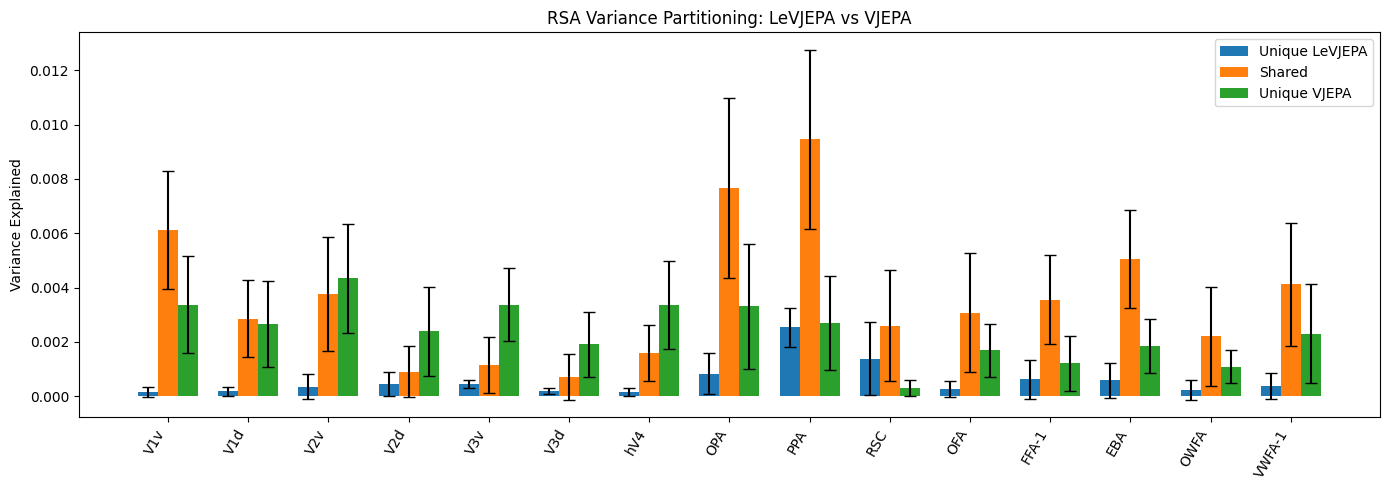

Plot saved:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots\LeVJEPA_vs_VJEPA_UVP.png


UVP: LeVJEPA vs VideoMAE

Loading RSA results...
Common ROIs: 15

------------------------------------------------------------
Processing ROI: EBA
LeVJEPA layer: RDM_layer_8.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: FFA-1
LeVJEPA layer: RDM_layer_8.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OFA
LeVJEPA layer: RDM_layer_8.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OPA
LeVJEPA layer: RDM_layer_8.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OWFA
LeVJEPA layer: RDM_layer_8.npz
VideoMAE 

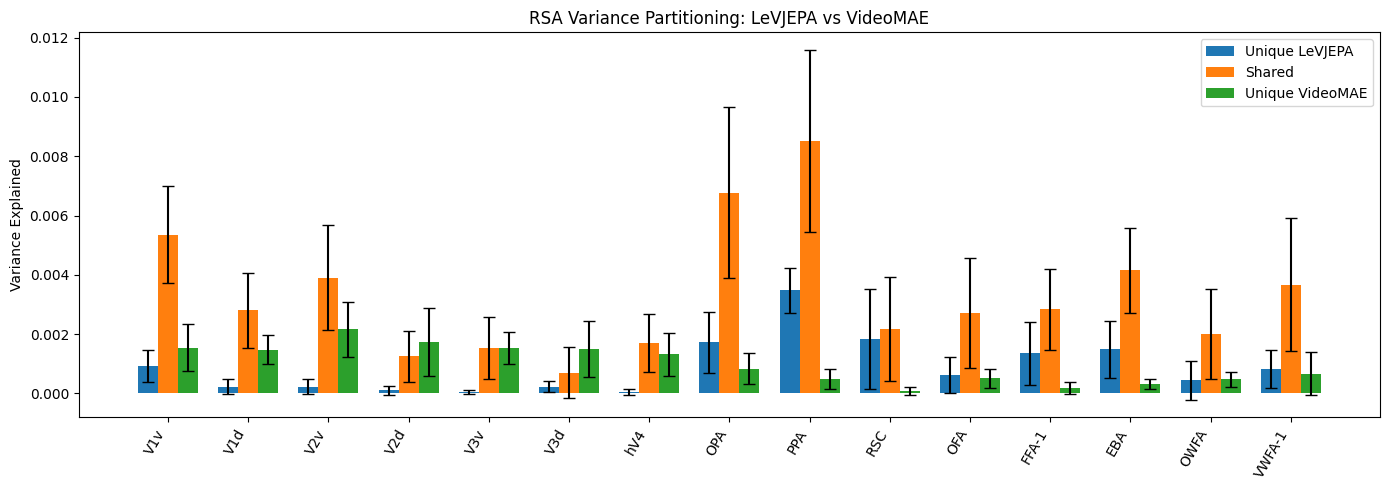

Plot saved:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots\LeVJEPA_vs_VideoMAE_UVP.png


UVP: LeVJEPA vs DINOv2

Loading RSA results...
Common ROIs: 15

------------------------------------------------------------
Processing ROI: EBA
LeVJEPA layer: RDM_layer_8.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: FFA-1
LeVJEPA layer: RDM_layer_8.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OFA
LeVJEPA layer: RDM_layer_8.npz
DINOv2 layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OPA
LeVJEPA layer: RDM_layer_8.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OWFA
LeVJEPA layer: RDM_layer_8.npz
DINOv2 layer:

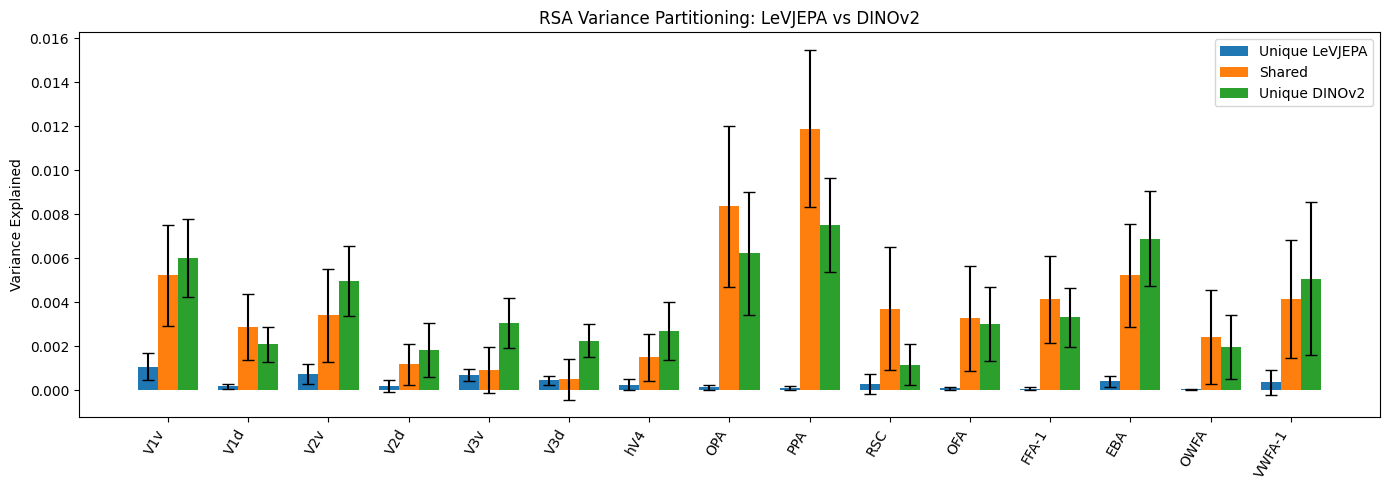

Plot saved:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots\LeVJEPA_vs_DINOv2_UVP.png


UVP: VJEPA vs VideoMAE

Loading RSA results...
Common ROIs: 15

------------------------------------------------------------
Processing ROI: EBA
VJEPA layer: RDM_layer_12.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: FFA-1
VJEPA layer: RDM_layer_11.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OFA
VJEPA layer: RDM_layer_11.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OPA
VJEPA layer: RDM_layer_11.npz
VideoMAE layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OWFA
VJEPA layer: RDM_layer_11.npz
VideoMAE layer:

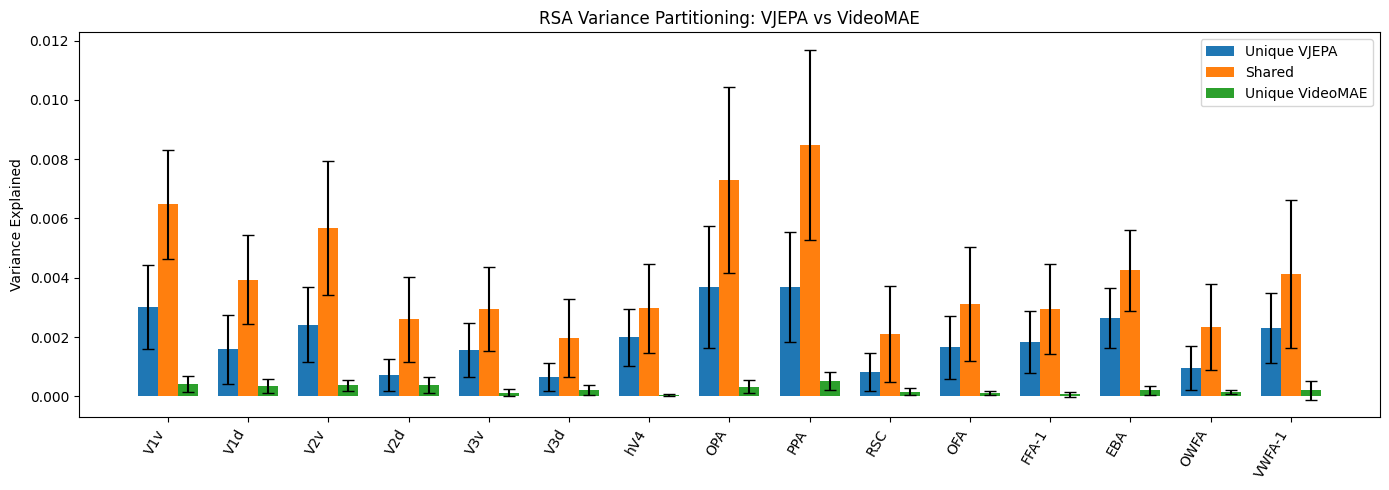

Plot saved:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots\VJEPA_vs_VideoMAE_UVP.png


UVP: VJEPA vs DINOv2

Loading RSA results...
Common ROIs: 15

------------------------------------------------------------
Processing ROI: EBA
VJEPA layer: RDM_layer_12.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: FFA-1
VJEPA layer: RDM_layer_11.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OFA
VJEPA layer: RDM_layer_11.npz
DINOv2 layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OPA
VJEPA layer: RDM_layer_11.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OWFA
VJEPA layer: RDM_layer_11.npz
DINOv2 layer: RDM_laye

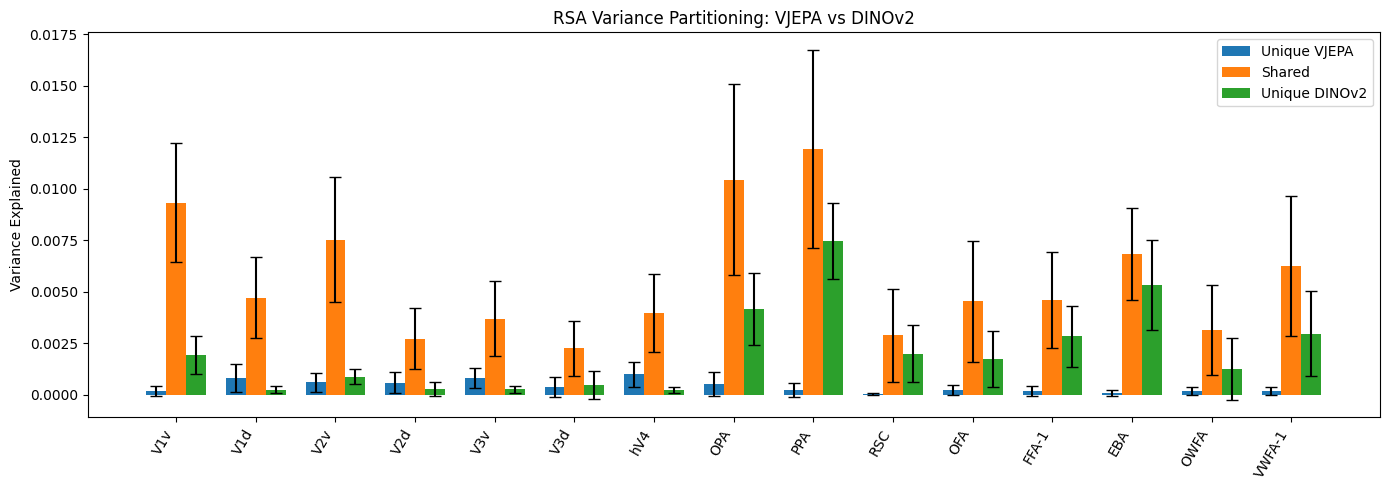

Plot saved:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots\VJEPA_vs_DINOv2_UVP.png


UVP: VideoMAE vs DINOv2

Loading RSA results...
Common ROIs: 15

------------------------------------------------------------
Processing ROI: EBA
VideoMAE layer: RDM_layer_9.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: FFA-1
VideoMAE layer: RDM_layer_9.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OFA
VideoMAE layer: RDM_layer_9.npz
DINOv2 layer: RDM_layer_9.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OPA
VideoMAE layer: RDM_layer_9.npz
DINOv2 layer: RDM_layer_10.npz
Brain RDM shape: (8, 872, 872)

------------------------------------------------------------
Processing ROI: OWFA
VideoMAE layer: RDM_layer_9.npz
DINOv2 laye

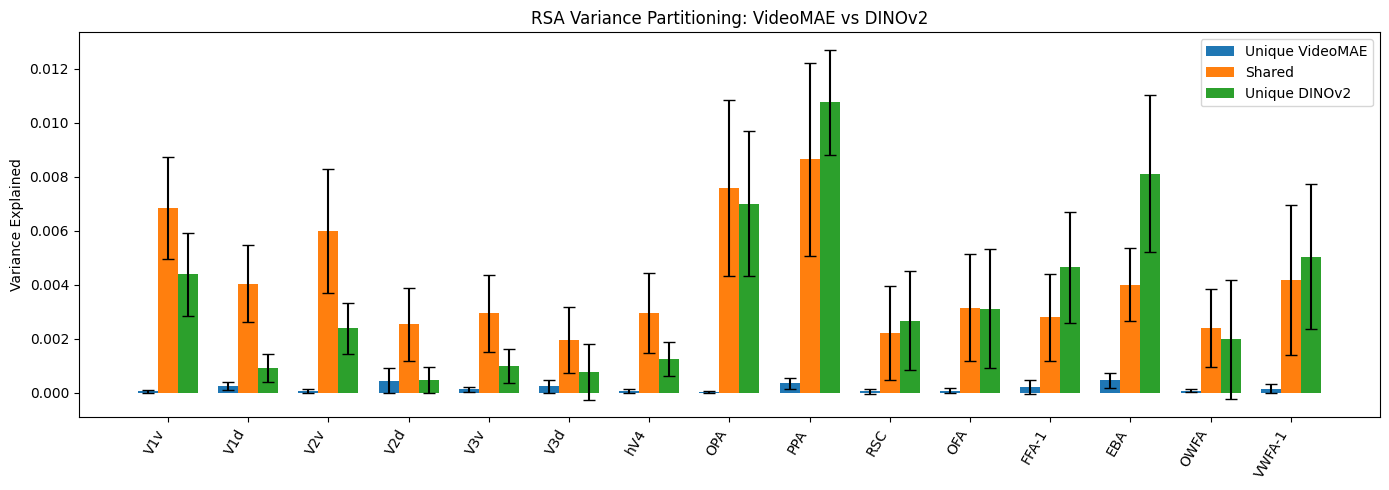

Plot saved:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots\VideoMAE_vs_DINOv2_UVP.png


VIDEO UVP ANALYSES AND PLOTS COMPLETE

CSV results:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA results

Plots:
C:\Users\louai\Net2Brain\notebooks\0_RSA results\UVP\UVP RSA plots


In [13]:
import os
import glob
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from net2brain.evaluations.variance_partitioning_analysis import VPA


# ============================================================
# SETTINGS
# ============================================================

# ------------------------------------------------------------
# Output folders
# ------------------------------------------------------------

results_output = (
    "PATH"
    "PATH"
)

plots_output = (
    "PATH"
    "PATH"
)

os.makedirs(results_output, exist_ok=True)
os.makedirs(plots_output, exist_ok=True)


# ------------------------------------------------------------
# Brain RDMs
# ------------------------------------------------------------

brain_rdms = (
    "PATH"
    "PATH"
    "PATH"
)


# ------------------------------------------------------------
# RSA RESULT FILES
#
# Used ONLY to select the best-performing layer for each ROI.
# ------------------------------------------------------------

rsa_root = (
    "PATH"
    "PATH"
)

rsa_paths = {

    # =========================
    # ViT-L
    # =========================

    "LeJEPA": os.path.join(
        rsa_root,
        "PATH"
    ),

    "MAE": os.path.join(
        rsa_root,
        "PATH"
    ),

    "IBOT": os.path.join(
        rsa_root,
        "PATH"
    ),


    # =========================
    # ViT-B
    # =========================

    "DINOv1": os.path.join(
        rsa_root,
        "PATH"
    ),

    "LeJEPA-B": os.path.join(
        rsa_root,
        "PATH"
    ),


    # =========================
    # Vision-language
    # =========================

    "LeVLJEPA": os.path.join(
        rsa_root,
        "PATH"
    ),

    "InfoNCE": os.path.join(
        rsa_root,
        "PATH"
    ),

    "OpenCLIP": os.path.join(
        rsa_root,
        "PATH"
    ),


    # =========================
    # Video
    # =========================

    "LeVJEPA": os.path.join(
        rsa_root,
        "PATH"
    ),

    "VJEPA": os.path.join(
        rsa_root,
        "PATH"
    ),

    "VideoMAE": os.path.join(
        rsa_root,
        "PATH"
    ),

    "DINOv2": os.path.join(
        rsa_root,
        "PATH"
    ),
}



# ------------------------------------------------------------
# MODEL RDM FOLDERS
# ------------------------------------------------------------

rdm_root = "PATH"

rdm_paths = {

    # =========================
    # ViT-L
    # =========================
    

    "LeJEPA": os.path.join(
        rdm_root,
        "PATH"
    ),

    "MAE": os.path.join(
        rdm_root,
        "PATH"
    ),

    "IBOT": os.path.join(
        rdm_root,
        "PATH"
    ),


    # =========================
    # ViT-B
    # =========================

    "DINOv1": os.path.join(
        rdm_root,
        "PATH"
    ),

    "LeJEPA-B": os.path.join(
        rdm_root,
        "PATH"
    ),


    # =========================
    # Vision-language
    # =========================

    "LeVLJEPA": os.path.join(
        rdm_root,
        "PATH"
    ),

    "InfoNCE": os.path.join(
        rdm_root,
        "PATH"
    ),

    "OpenCLIP": os.path.join(
        rdm_root,
        "PATH"
    ),


    # =========================
    # Video
    # =========================

    "LeVJEPA": os.path.join(
        rdm_root,
        "PATH"
    ),

    "VJEPA": os.path.join(
        rdm_root,
        "PATH"
    ),

    "VideoMAE": os.path.join(
        rdm_root,
        "PATH"
    ),

    "DINOv2": os.path.join(
        rdm_root,
        "PATH"
    ),
}


# ============================================================
# MODEL GROUPS
# ============================================================

model_groups = {

    "vitl": [
        "LeJEPA",
        "MAE",
        "IBOT",
    ],

    "vitb": [
        "LeJEPA-B",
        "DINOv1",
    ],

    "vl": [
        "LeVLJEPA",
        "InfoNCE",
        "OpenCLIP",
    ],

    "video": [
        "LeVJEPA",
        "VJEPA",
        "VideoMAE",
        "DINOv2",
    ],
}


# ============================================================
# ROI ORDER
# ============================================================

roi_order = [
    "V1v", "V1d",
    "V2v", "V2d",
    "V3v", "V3d",
    "hV4",
    "OPA", "PPA", "RSC",
    "OFA", "FFA-1", "EBA",
    "OWFA", "VWFA-1"
]


# ============================================================
# HELPER: CLEAN ROI NAME
# ============================================================

def clean_roi_name(roi):

    roi = str(roi).strip()

    # Remove leading "(0) ", "(1) ", etc.
    roi = re.sub("PATH", roi)

    # Remove leading "0 ", "1 ", etc. if present
    roi = re.sub("PATH", roi)

    # Remove RDM suffixes if present
    roi = re.sub(
        "PATH",
        "",
        roi
    )

    # Remove other combined suffixes if present
    roi = re.sub(
        "PATH",
        "",
        roi
    )

    return roi


# ============================================================
# HELPER: LOAD RSA DATA
# ============================================================

def load_rsa_dataframe(model):

    path = rsa_paths[model]

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"\nRSA file does not exist for {model}:\n{path}"
        )

    df = pd.read_csv(path)

    # Clean ROI names so the same ROI can be matched
    # between models and brain RDMs.
    df["ROI"] = df["ROI"].apply(clean_roi_name)

    return df


# ============================================================
# HELPER: FIND BEST RSA LAYER
# ============================================================

def get_best_layers(model):

    df = load_rsa_dataframe(model)

    # Make sure R2 exists
    if "R2" not in df.columns:

        if "R" in df.columns:
            df["R2"] = df["R"] ** 2

        else:
            raise ValueError(
                f"No R2 or R column found in RSA results for {model}"
            )

    # Highest R2 = best layer for that ROI
    best = (
        df.sort_values("R2", ascending=False)
        .groupby("ROI")
        .first()
    )

    return best


# ============================================================
# HELPER: GET ACTUAL LAYER NAME
# ============================================================

def extract_layer_name(layer):

    layer = str(layer)

    # RSA layers are often stored as:
    #
    # "(12) visual.transformer..."
    #
    # We only need the actual folder name.

    if ") " in layer:
        return layer.split(") ", 1)[1]

    return layer


# ============================================================
# RUN UVP FOR ONE MODEL PAIR
# ============================================================

def run_uvp(model1, model2):

    print("\n")
    print("=" * 80)
    print(f"UVP: {model1} vs {model2}")
    print("=" * 80)


    # --------------------------------------------------------
    # Best RSA layers
    # --------------------------------------------------------

    print("\nLoading RSA results...")

    best_model1 = get_best_layers(model1)
    best_model2 = get_best_layers(model2)


    # Only use ROIs present in both models
    common_rois = [
        roi for roi in best_model1.index
        if roi in best_model2.index
    ]

    print(f"Common ROIs: {len(common_rois)}")


    all_results = []


    # ========================================================
    # ROI LOOP
    # ========================================================

    for roi in common_rois:

        print("\n" + "-" * 60)
        print(f"Processing ROI: {roi}")


        # ----------------------------------------------------
        # Best layer
        # ----------------------------------------------------

        model1_row = best_model1.loc[roi]
        model2_row = best_model2.loc[roi]

        model1_layer = extract_layer_name(
            model1_row["Layer"]
        )

        model2_layer = extract_layer_name(
            model2_row["Layer"]
        )

        print(f"{model1} layer: {model1_layer}")
        print(f"{model2} layer: {model2_layer}")


        # ----------------------------------------------------
        # Model RDM paths
        # ----------------------------------------------------

        model1_rdm = os.path.join(
            rdm_paths[model1],
            model1_layer
        )

        model2_rdm = os.path.join(
            rdm_paths[model2],
            model2_layer
        )


        # ----------------------------------------------------
        # Check RDM paths
        # ----------------------------------------------------

        if not os.path.exists(model1_rdm):

            raise FileNotFoundError(
                f"\nModel RDM not found:\n"
                f"{model1_rdm}\n\n"
                f"Model: {model1}\n"
                f"ROI: {roi}\n"
                f"Layer: {model1_layer}"
            )

        if not os.path.exists(model2_rdm):

            raise FileNotFoundError(
                f"\nModel RDM not found:\n"
                f"{model2_rdm}\n\n"
                f"Model: {model2}\n"
                f"ROI: {roi}\n"
                f"Layer: {model2_layer}"
            )


        # ----------------------------------------------------
        # Brain RDM
        #
        # Actual files are named:
        # EBA_combined_RDMs.npz
        # FFA-1_combined_RDMs.npz
        # ...
        # ----------------------------------------------------
        
        brain_file = os.path.join(
            brain_rdms,
            f"PATH"
        )
        
        if not os.path.exists(brain_file):
        
            raise FileNotFoundError(
                f"\nBrain RDM not found:\n{brain_file}"
            )


        # ----------------------------------------------------
        # Load brain RDM
        #
        # Expected:
        #
        # (8, 872, 872)
        #
        # = 8 subjects
        # = 872 images
        # ----------------------------------------------------

        x = np.load(
            brain_file,
            allow_pickle=True
        )["rdm"]

        print(f"Brain RDM shape: {x.shape}")


        # ----------------------------------------------------
        # Create VPA object
        # ----------------------------------------------------

        vpa = VPA(
            dependent_variable=[brain_file],

            independent_variables=[
                model1_rdm,
                model2_rdm
            ],

            variable_names=[
                model1,
                model2
            ]
        )


        # ----------------------------------------------------
        # Net2Brain workaround
        # ----------------------------------------------------

        vpa.independent_1 = [
            vpa.independent_1
        ]

        vpa.independent_2 = [
            vpa.independent_2
        ]

        vpa.average_models = False


        # ----------------------------------------------------
        # Convert each subject's brain RDM
        # into an upper-triangular vector
        # ----------------------------------------------------

        dep_var = np.array([
            vpa.get_uppertriangular(subject)
            for subject in x
        ])

        # Shape:
        #
        # (subjects, 1, pairwise_distances)
        #

        dep_var = dep_var[:, None, :]


        # ----------------------------------------------------
        # Load model RDMs
        # ----------------------------------------------------

        vpa.load_rdms(
            vpa.independent_1
        )

        vpa.load_rdms(
            vpa.independent_2
        )


        # ----------------------------------------------------
        # Variance partitioning
        # ----------------------------------------------------

        vp = vpa.VPA_function(
            dep_var,

            num_subjects=dep_var.shape[0],

            eeg_time=dep_var.shape[1]
        )


        # ----------------------------------------------------
        # Extract variance components
        #
        # y1  = unique model 1
        # y12 = shared
        # y2  = unique model 2
        # ----------------------------------------------------

        unique_model1_values = np.array(
            vp.loc[
                vp["Variable"] == "y1",
                "Values"
            ].iloc[0]
        ).flatten()

        shared_values = np.array(
            vp.loc[
                vp["Variable"] == "y12",
                "Values"
            ].iloc[0]
        ).flatten()

        unique_model2_values = np.array(
            vp.loc[
                vp["Variable"] == "y2",
                "Values"
            ].iloc[0]
        ).flatten()


        # ----------------------------------------------------
        # Mean across subjects
        # ----------------------------------------------------

        unique_model1 = (
            unique_model1_values.mean()
        )

        shared = (
            shared_values.mean()
        )

        unique_model2 = (
            unique_model2_values.mean()
        )


        # ----------------------------------------------------
        # SD across subjects
        # ----------------------------------------------------

        unique_model1_std = (
            unique_model1_values.std(ddof=1)
        )

        shared_std = (
            shared_values.std(ddof=1)
        )

        unique_model2_std = (
            unique_model2_values.std(ddof=1)
        )


        # ----------------------------------------------------
        # Save ROI result
        # ----------------------------------------------------

        all_results.append({

            "ROI": roi,

            f"Best_{model1}_Layer":
                model1_layer,

            f"Best_{model2}_Layer":
                model2_layer,

            f"{model1}_RSA_R2":
                model1_row["R2"],

            f"{model2}_RSA_R2":
                model2_row["R2"],

            f"Unique_{model1}":
                unique_model1,

            f"Unique_{model1}_STD":
                unique_model1_std,

            "Shared":
                shared,

            "Shared_STD":
                shared_std,

            f"Unique_{model2}":
                unique_model2,

            f"Unique_{model2}_STD":
                unique_model2_std,
        })


    # ========================================================
    # CREATE DATAFRAME
    # ========================================================

    results_df = pd.DataFrame(
        all_results
    )


    # ========================================================
    # SORT ROIs ANATOMICALLY
    # ========================================================

    results_df["ROI"] = pd.Categorical(
        results_df["ROI"],
        categories=roi_order,
        ordered=True
    )

    results_df = (
        results_df
        .sort_values("ROI")
        .reset_index(drop=True)
    )


    # ========================================================
    # SAVE CSV
    # ========================================================

    csv_name = (
        f"rsa_uvp_"
        f"{model1.lower()}_"
        f"{model2.lower()}_"
        f"all_rois.csv"
    )

    csv_path = os.path.join(
        results_output,
        csv_name
    )

    results_df.to_csv(
        csv_path,
        index=False
    )

    print(
        f"\nCSV saved:\n{csv_path}"
    )


    # ========================================================
    # PLOT
    # ========================================================

    x = np.arange(
        len(results_df)
    )

    width = 0.25


    fig, ax = plt.subplots(
        figsize=(14, 5)
    )


    # --------------------------------------------------------
    # Unique model 1
    # --------------------------------------------------------

    ax.bar(
        x - width,

        results_df[
            f"Unique_{model1}"
        ],

        width,

        yerr=results_df[
            f"Unique_{model1}_STD"
        ],

        capsize=4,

        label=f"Unique {model1}"
    )


    # --------------------------------------------------------
    # Shared
    # --------------------------------------------------------

    ax.bar(
        x,

        results_df["Shared"],

        width,

        yerr=results_df[
            "Shared_STD"
        ],

        capsize=4,

        label="Shared"
    )


    # --------------------------------------------------------
    # Unique model 2
    # --------------------------------------------------------

    ax.bar(
        x + width,

        results_df[
            f"Unique_{model2}"
        ],

        width,

        yerr=results_df[
            f"Unique_{model2}_STD"
        ],

        capsize=4,

        label=f"Unique {model2}"
    )


    # --------------------------------------------------------
    # X-axis
    # --------------------------------------------------------

    ax.set_xticks(x)

    ax.set_xticklabels(
        results_df["ROI"],
        rotation=60,
        ha="right"
    )


    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_ylabel(
        "Variance Explained"
    )

    ax.set_xlabel("")


    ax.set_title(
        f"RSA Variance Partitioning: "
        f"{model1} vs {model2}"
    )


    ax.legend()


    plt.tight_layout()


    # ========================================================
    # SAVE PLOT
    # ========================================================

    plot_name = (
        f"{model1}_vs_{model2}_UVP.png"
    )

    plot_path = os.path.join(
        plots_output,
        plot_name
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


    print(
        f"Plot saved:\n{plot_path}"
    )

    return results_df


# ============================================================
# GENERATE ALL PAIRWISE COMPARISONS
# ============================================================

for group_name, models in model_groups.items():

    print("\n")
    print("#" * 80)
    print(f"GROUP: {group_name.upper()}")
    print("#" * 80)

    pairs = list(
        itertools.combinations(
            models,
            2
        )
    )

    for model1, model2 in pairs:

        run_uvp(
            model1,
            model2
        )


print("\n")
print("=" * 80)
print("ALL UVP ANALYSES AND PLOTS COMPLETE")
print("=" * 80)

print(
    f"\nCSV results:\n{results_output}"
)

print(
    f"\nPlots:\n{plots_output}"
)

# visualizing UVP

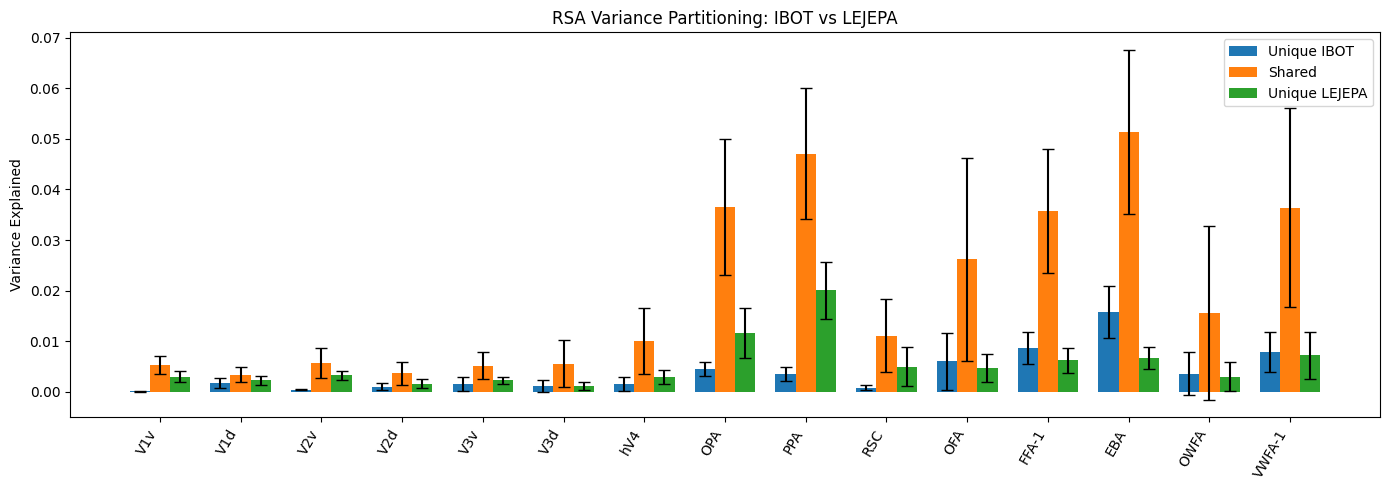

In [6]:
# ============================================================
# PLOT RSA UVP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plot_df = results_df.copy()

# Remove "(0) " etc.
plot_df["ROI"] = plot_df["ROI"].astype(str).str.replace(
    "PATH", regex=True
)

# Extract actual ROI name
plot_df["ROI_base"] = plot_df["ROI"].str.extract(
    "PATH",
    expand=False
)

# Desired anatomical order
roi_order = [
    "V1v", "V1d",
    "V2v", "V2d",
    "V3v", "V3d",
    "hV4",
    "OPA", "PPA", "RSC",
    "OFA", "FFA-1", "EBA",
    "OWFA", "VWFA-1"
]

# Apply anatomical order
plot_df["ROI_base"] = pd.Categorical(
    plot_df["ROI_base"],
    categories=roi_order,
    ordered=True
)

plot_df = (
    plot_df
    .sort_values("ROI_base")
    .reset_index(drop=True)
)

# ============================================================
# CREATE BAR PLOT
# ============================================================

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(14, 5))

plt.bar(
    x - width,
    plot_df[f"Unique_{model1}"],
    width,
    yerr=plot_df[f"Unique_{model1}_STD"],
    capsize=4,
    label=f"Unique {model1}"
)

plt.bar(
    x,
    plot_df["Shared"],
    width,
    yerr=plot_df["Shared_STD"],
    capsize=4,
    label="Shared"
)

plt.bar(
    x + width,
    plot_df[f"Unique_{model2}"],
    width,
    yerr=plot_df[f"Unique_{model2}_STD"],
    capsize=4,
    label=f"Unique {model2}"
)

plt.xticks(
    x,
    plot_df["ROI_base"],
    rotation=60,
    ha="right"
)

plt.ylabel("Variance Explained")

plt.title(
    f"RSA Variance Partitioning: {model1} vs {model2}"
)

plt.legend()

plt.tight_layout()

plt.show()

In [2]:
#load the three matrices
import os
import glob
import numpy as np

ibot_folder = "PATH"
lejepa_folder = "PATH"
fmri_path = "PATH"

ibot_files = sorted(glob.glob(os.path.join(ibot_folder, "*.npz")))
lejepa_files = sorted(glob.glob(os.path.join(lejepa_folder, "*.npz")))

X_ibot = np.vstack([
    np.load(f)["layer_20"]
    for f in ibot_files
])

X_lejepa = np.vstack([
    np.load(f)["layer_17"]
    for f in lejepa_files
])

Y = np.load(fmri_path)

print("Number of IBOT files:", len(ibot_files))
print("Number of LeJEPA files:", len(lejepa_files))
print("IBOT:", X_ibot.shape)
print("LeJEPA:", X_lejepa.shape)
print("fMRI:", Y.shape)

Number of IBOT files: 872
Number of LeJEPA files: 872
IBOT: (872, 1024)
LeJEPA: (872, 1024)
fMRI: (872, 6237)


In [4]:
#standardize them
from sklearn.preprocessing import StandardScaler

scaler_ibot = StandardScaler()
scaler_lejepa = StandardScaler()
scaler_fmri = StandardScaler()

X_ibot_z = scaler_ibot.fit_transform(X_ibot)
X_lejepa_z = scaler_lejepa.fit_transform(X_lejepa)
Y_z = scaler_fmri.fit_transform(Y)

print("IBOT:", X_ibot_z.shape)
print("LeJEPA:", X_lejepa_z.shape)
print("fMRI:", Y_z.shape)

print("IBOT mean/std:", X_ibot_z.mean(), X_ibot_z.std())
print("LeJEPA mean/std:", X_lejepa_z.mean(), X_lejepa_z.std())
print("fMRI mean/std:", Y_z.mean(), Y_z.std())

IBOT: (872, 1024)
LeJEPA: (872, 1024)
fMRI: (872, 6237)
IBOT mean/std: 4.2721217e-12 0.99999994
LeJEPA mean/std: -1.4311609e-10 1.0
fMRI mean/std: 8.004766e-11 0.99999976


In [5]:
Fit the joint banded ridge model on all 872 images
from himalaya.kernel_ridge import solve_multiple_kernel_ridge_random_search
import numpy as np

# --------------------------------------------------
# Build kernels from standardized features
# --------------------------------------------------

K_ibot = X_ibot_z @ X_ibot_z.T
K_lejepa = X_lejepa_z @ X_lejepa_z.T

Ks = np.stack([K_ibot, K_lejepa])

print("Kernel shape:", Ks.shape)

# --------------------------------------------------
# Fit joint model on ALL 872 images
# --------------------------------------------------

deltas, weights, cv_scores, best_alphas = solve_multiple_kernel_ridge_random_search(
    Ks=Ks,
    Y=Y_z,
    n_iter=100,
    alphas=np.logspace(-2, 2, 9),      # 0.01 ... 100
    cv=5,
    Xs=[X_ibot_z, X_lejepa_z],
    return_weights="primal",
    return_alphas=True,
    random_state=42,
    progress_bar=True
)

print("\nDone.")
print("Weights:", weights.shape)
print("Best alphas:", best_alphas.shape)
print("Deltas:", deltas.shape)

print("\nAlpha statistics")
print("Mean alpha:", best_alphas.mean())
print("Median alpha:", np.median(best_alphas))
print("Unique alphas:", np.unique(best_alphas))

Kernel shape: (2, 872, 872)
[..............................] 100% | 456.95 sec | 100 random sampling with cv | 0.22 it/s, ETA: 00:00:00

Done.
Weights: (2048, 6237)
Best alphas: (6237,)
Deltas: (2, 6237)

Alpha statistics
Mean alpha: 100.0
Median alpha: 100.0
Unique alphas: [100.]


In [6]:
#Let's do plain sklearn.linear_model.LinearRegression, using all 872 images, with your already-standardized matrices.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Fit IBOT -> fMRI
model_ibot = LinearRegression()
model_ibot.fit(X_ibot_z, Y_z)

# Predict all 872 images
Y_pred_ibot = model_ibot.predict(X_ibot_z)

# R² for each voxel
r2_ibot = r2_score(Y_z, Y_pred_ibot, multioutput="raw_values")

print("Prediction shape:", Y_pred_ibot.shape)
print("R² shape:", r2_ibot.shape)
print("Mean R²:", r2_ibot.mean())
print("Median R²:", np.median(r2_ibot))
print("Positive R² voxels:", (r2_ibot > 0).sum(), "/", r2_ibot.size)

Prediction shape: (872, 6237)
R² shape: (6237,)
Mean R²: 1.0
Median R²: 1.0
Positive R² voxels: 6237 / 6237


In [7]:
#IBOT linear regression → Pearson r
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
import numpy as np

model_ibot = LinearRegression()
model_ibot.fit(X_ibot_z, Y_z)

Y_pred_ibot = model_ibot.predict(X_ibot_z)

# Pearson r for each voxel
r_ibot = np.array([
    pearsonr(Y_pred_ibot[:, v], Y_z[:, v])[0]
    for v in range(Y_z.shape[1])
])

r2_ibot = r_ibot ** 2

print("Mean Pearson r:", r_ibot.mean())
print("Median Pearson r:", np.median(r_ibot))
print("Mean r²:", r2_ibot.mean())
print("Median r²:", np.median(r2_ibot))

Mean Pearson r: 1.0
Median Pearson r: 1.0
Mean r²: 1.0
Median r²: 1.0


In [8]:
from sklearn.linear_model import Ridge

# Try a single alpha first
alpha_ibot = 1.0

ridge_ibot = Ridge(alpha=alpha_ibot)
ridge_ibot.fit(X_ibot_z, Y_z)

Y_pred_ibot = ridge_ibot.predict(X_ibot_z)

r2_ibot = 1 - np.sum((Y_z - Y_pred_ibot)**2, axis=0) / np.sum(Y_z**2, axis=0)

print("Mean R²:", r2_ibot.mean())
print("Median R²:", np.median(r2_ibot))

Mean R²: 0.9976787
Median R²: 0.99770856
